# 01d · Modelo base: predecir las llegadas

**Propósito (paso 11 del plan).** Construir un modelo sencillo que prediga cuántos vehículos llegan a cada acceso en un intervalo de 15 minutos (`llegadas`), a partir de lo que sabríamos **antes** de que ocurra: acceso, hora, tipo de día, lluvia y evento en el Madison Square Garden. Lo comparamos contra una referencia simple y lo evaluamos con datos que no vio al entrenar.

**¿Para qué sirve en el proyecto?** SimPy necesita una tasa de llegada λ para cada acceso y momento. Este modelo es la forma de obtener esa λ **a partir de los datos**, en lugar de copiarla de las reglas.

> **Advertencia de honestidad.** La base es ficticia. Si el modelo acierta, demuestra que **recupera las reglas con que generamos los datos**; no dice nada sobre el tráfico real.

## 0. Preparación

Cargamos `intervalos` y definimos:

- **Variable objetivo:** `llegadas` (un conteo: 0, 1, 2, …).
- **Predictoras:** `acceso_id`, `hora`, `tipo_dia`, `lluvia`, `evento_msg`.
- **Excluida a propósito: `tasa_llegada_vph`.** Es la λ que el generador usó para sortear las llegadas. Usarla sería **fuga de información**: el modelo copiaría la respuesta en vez de aprenderla, y en la vida real nadie conoce esa λ por adelantado.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
iv = pd.read_csv(RAIZ / 'datos/procesados/intervalos.csv')
iv['hora'] = iv['hora_inicio'].str[:2].astype(int)
ACCESOS = {33804: 'Séptima SB', 33803: 'W30 EB', 33894: 'W29 WB'}
iv['acceso'] = iv['acceso_id'].map(ACCESOS)
# Combinamos acceso, hora y tipo de día en una sola etiqueta: cada acceso tiene su propio perfil
# horario y ese perfil cambia el fin de semana (así lo dice la regla λ_base(acceso, hora, tipo_dia)).
iv['perfil'] = iv['acceso'] + '|' + iv['hora'].astype(str) + '|' + iv['tipo_dia']
X_COLS = ['perfil', 'lluvia', 'evento_msg']
y = iv['llegadas']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(iv.shape, '| perfiles distintos:', iv['perfil'].nunique())

(2016, 16) | perfiles distintos: 144


**Lectura.** Hay 2,016 intervalos y 144 perfiles (3 accesos × 24 horas × 2 tipos de día). Cada perfil tiene unas 4 a 20 observaciones, según cuántos días de ese tipo haya en la semana.

## 1. Tres modelos, de menos a más

1. **Referencia (sin aprendizaje):** predecir el promedio histórico del mismo perfil (acceso, hora y tipo de día). Ignora lluvia y evento. Es lo que haría alguien con una hoja de cálculo y lo que hay que superar.
2. **Regresión lineal:** `llegadas = perfil + efecto_lluvia + efecto_evento`. Los efectos se **suman**: la lluvia fuerte quitaría, por ejemplo, 15 carros a las 3 a. m. y también a las 6 p. m.
3. **Regresión de Poisson:** `log(μ) = perfil + efecto_lluvia + efecto_evento`, es decir, `μ = e^perfil × e^lluvia × e^evento`. Los efectos se **multiplican**: la lluvia quita un **porcentaje**. Además supone que el conteo varía como una Poisson, como en el generador.

Analogía: si la lluvia hace que el 15 % de la gente se quede en casa, en una calle con 40 carros faltan 6, y en una con 300 faltan 45. El modelo lineal no puede expresar eso; el de Poisson sí.

In [2]:
def referencia(train, test):
    medias = train.groupby('perfil')['llegadas'].mean()
    return test['perfil'].map(medias).fillna(train['llegadas'].mean()).to_numpy()

def ajustar(modelo, train, test):
    pipe = make_pipeline(OneHotEncoder(handle_unknown='ignore'), modelo)
    pipe.fit(train[X_COLS], train['llegadas'])
    return pipe.predict(test[X_COLS]), pipe

MODELOS = {
    'Referencia': None,
    'Lineal': LinearRegression(),
    'Poisson': PoissonRegressor(alpha=1e-4, max_iter=3000),
}
def predecir(nombre, train, test):
    if MODELOS[nombre] is None: return referencia(train, test)
    return ajustar(MODELOS[nombre], train, test)[0]

**Lectura.** Las tres funciones reciben un conjunto de entrenamiento y otro de prueba; así las evaluamos exactamente igual. `OneHotEncoder` convierte cada categoría en una columna de ceros y unos. La pequeña penalización `alpha` del modelo de Poisson solo evita coeficientes inestables.

## 2. ¿Cómo separar entrenamiento y prueba?

El plan pide una **separación cronológica**: entrenar con el pasado y probar con el futuro. Con una sola semana surge un problema: el fin de semana está al final. Si entrenamos de lunes a viernes y probamos sábado y domingo, el modelo **nunca vio un fin de semana**. Lo comprobamos primero.

**Métricas** (ambas en vehículos por intervalo de 15 min):

- **MAE** = promedio de |real − predicho|. “En promedio me equivoco por X carros”.
- **RMSE** = raíz del promedio de (real − predicho)². Castiga más los errores grandes.

In [3]:
def metricas(y_real, y_pred):
    return {'MAE': mean_absolute_error(y_real, y_pred), 'RMSE': mean_squared_error(y_real, y_pred) ** 0.5}

train = iv[iv.tipo_dia == 'laborable']; test = iv[iv.tipo_dia != 'laborable']
pd.DataFrame({n: metricas(test['llegadas'], predecir(n, train, test)) for n in MODELOS}).T.round(1)

,MAE,RMSE
Referencia,62.8,70.2
Lineal,62.5,70.1
Poisson,49.9,65.5


**Lectura.** Los errores son enormes (MAE de 50 a 63 carros, frente a unos 10 en la validación siguiente): los perfiles de fin de semana no existen en el entrenamiento, y los modelos solo pueden adivinar con un promedio. Es una lección de **generalización**: un modelo no extrapola a condiciones que nunca observó. Con una semana de datos, una separación cronológica pura no es viable.

## 3. Validación por días completos (dejar un día fuera)

Alternativa honesta: repetimos 7 veces el ejercicio. En cada vuelta **apartamos un día completo** (sus 288 intervalos), entrenamos con los otros 6 y predecimos el día apartado.

- Se separa por **día completo**, no por intervalos sueltos. Si mezcláramos las 17:00 y las 17:15 del mismo día entre entrenamiento y prueba, el modelo “vería” ese día (su factor diario `f_día` y su lluvia) y el error saldría optimista. Esa es otra forma de fuga de información.
- Los modelos no usan rezagos ni tendencias, así que entrenar con días posteriores al de prueba no les da información del futuro.

In [4]:
filas = []
for fecha in sorted(iv['fecha'].unique()):
    tr, te = iv[iv.fecha != fecha], iv[iv.fecha == fecha]
    for n in MODELOS:
        filas.append({'fecha_prueba': fecha, 'modelo': n, **metricas(te['llegadas'], predecir(n, tr, te))})
cv = pd.DataFrame(filas)
resumen = cv.groupby('modelo')[['MAE', 'RMSE']].mean().loc[list(MODELOS)]
# Piso de ruido: aun conociendo la λ verdadera (que el modelo NO puede usar), el azar de Poisson deja un error.
piso = metricas(iv['llegadas'], iv['tasa_llegada_vph'] * 0.25)
resumen.loc['Piso (λ verdadera)'] = piso
display(resumen.round(1))
cv.pivot(index='fecha_prueba', columns='modelo', values='MAE')[list(MODELOS)].round(1)

,MAE,RMSE
modelo,,
Referencia,10.0,14.6
Lineal,10.1,14.1
Poisson,9.7,13.6
Piso (λ verdadera),7.5,10.0


modelo,Referencia,Lineal,Poisson
fecha_prueba,,,
2026-03-02,10.1,10.5,9.1
2026-03-03,10.0,10.1,8.9
2026-03-04,11.5,11.8,11.7
2026-03-05,12.1,12.0,11.7
2026-03-06,11.2,11.2,11.6
2026-03-07,7.5,7.5,7.5
2026-03-08,7.5,7.5,7.5


**Lectura.** Con los datos de la semana, el MAE baja de 10.0 (referencia) a 9.7 (Poisson). La regresión lineal no mejora a la referencia. El **piso de ruido**, 7.5, es el error que tendría incluso alguien que conociera la λ exacta, porque las llegadas tienen azar. Ningún modelo puede bajar de ahí.

¿Por qué el Poisson no se acerca más al piso? Parte del hueco viene del factor diario `f_día` (cada día y cada acceso tienen un ±5 % aleatorio). Ese factor no se puede predecir con las variables disponibles.

Por día:
- **Lunes y martes** (días con evento) son donde el Poisson gana más (≈ 9 contra 10): aprende el efecto del evento con el otro día que lo tiene.
- **Viernes** (único con lluvia fuerte): al apartarlo, nadie vio lluvia fuerte y el Poisson empata o pierde un poco.
- **Sábado y domingo:** los tres modelos dan lo mismo. Al apartar uno, el perfil de fin de semana se aprende de **un solo día** y no hay lluvia ni evento que corregir. El error es más bajo solo porque el fin de semana hay menos tráfico.

## 4. ¿Recupera el modelo las reglas de generación?

En el modelo de Poisson, `e^coeficiente` es un **factor multiplicativo**. Ajustamos con los 7 días y comparamos los factores con las reglas (lluvia ligera 0.95 y fuerte 0.85). El factor del evento promedia la ventana de llegada y la de salida.

In [5]:
_, pipe = ajustar(PoissonRegressor(alpha=1e-4, max_iter=3000), iv, iv)
enc, reg = pipe.named_steps['onehotencoder'], pipe.named_steps['poissonregressor']
coef = pd.Series(reg.coef_, index=enc.get_feature_names_out(X_COLS))
f = lambda a, b: np.exp(coef[a] - coef[b])
pd.DataFrame({'factor estimado': [f('lluvia_ligera', 'lluvia_ninguna'), f('lluvia_fuerte', 'lluvia_ninguna'), f('evento_msg_sí', 'evento_msg_no')],
              'regla': [0.95, 0.85, 'depende de la ventana']},
             index=['lluvia ligera', 'lluvia fuerte', 'evento MSG']).round(3)

,factor estimado,regla
lluvia ligera,0.991,0.95
lluvia fuerte,0.871,0.85
evento MSG,1.150,depende de la ventana


**Lectura.** El factor de lluvia fuerte (0.87) se acerca a la regla (0.85). El de lluvia ligera sale 0.99: como vimos en `01c`, con pocos intervalos ese 5 % se pierde entre el ruido. Es decir, el modelo recupera los efectos grandes y no los pequeños. Con datos reales esto obliga a no prometer más precisión de la que los datos permiten.

## 5. Predicción contra realidad (día de prueba)

Como ejemplo, dibujamos el miércoles apartado: la Séptima, real contra predicho.

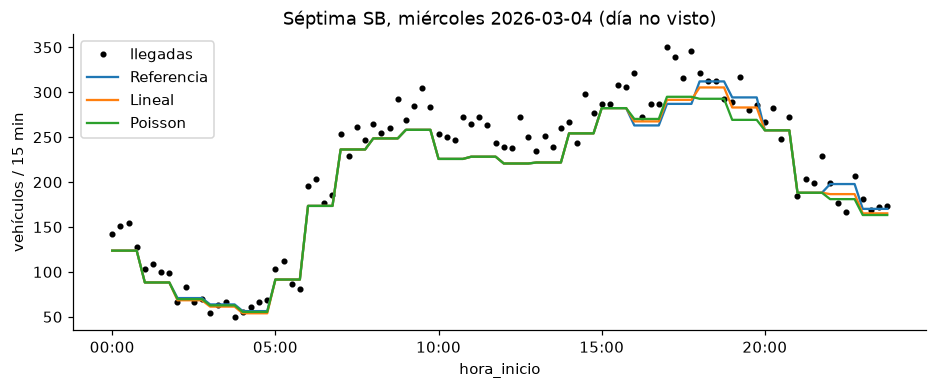

In [6]:
tr, te = iv[iv.fecha != '2026-03-04'], iv[iv.fecha == '2026-03-04'].copy()
for n in MODELOS: te[n] = predecir(n, tr, te)
s = te[te.acceso == 'Séptima SB']
ax = s.plot(x='hora_inicio', y=['llegadas'] + list(MODELOS), figsize=(10, 3.5), style=['k.', '-', '-', '-'])
ax.set_ylabel('vehículos / 15 min'); ax.set_title('Séptima SB, miércoles 2026-03-04 (día no visto)'); plt.show()

**Lectura.** Las tres curvas siguen la forma del día; los puntos reales oscilan alrededor de ellas por el azar de Poisson. El modelo no debe perseguir esos saltos: debe estimar el **promedio** μ, que es lo que SimPy necesita para sortear sus propias llegadas.

## Conclusiones

1. **Modelo elegido:** regresión de Poisson con perfil (acceso × hora × tipo de día), lluvia y evento. Supera a la referencia (MAE 9.7 contra 10.0; piso 7.5), sobre todo en los días con evento. La mejora es modesta porque casi toda la señal está en el perfil, que la referencia ya captura.
2. **Validación:** por días completos. La separación cronológica pura no es viable con una semana, porque el fin de semana y la lluvia fuerte quedarían fuera del entrenamiento.
3. **Fuga de información evitada:** se excluyó `tasa_llegada_vph` y se separó por día completo.
4. **Límite:** el modelo recupera las reglas grandes del generador (perfil, fin de semana, lluvia fuerte), pero no efectos pequeños como la lluvia ligera. Todo vale solo para datos sintéticos.
5. **Uso siguiente:** su predicción μ / 0.25 h da la λ por acceso y hora que alimentará las llegadas en SimPy (paso 12).